# Análise exploratória e scripts computacionais de Somativa02Resposta.ipynb

- **Repositório:** `analise-de-dados-fundamentos`  
- **Tecnologias:** Pandas, NumPy  
- **Arquivo Original:** `Somativa02Resposta.ipynb`  

---


# SOMATIVA 02 - TURMA C

## Estudante

In [ ]:
# Colocar seu nome aqui
# Victor Silva Camargo

### Conectar com Google drive

In [ ]:
from google.colab import drive
drive.mount('/content/gdrive')

Mounted at /content/gdrive


### Variáveis de ambiente para arquivos e conversão para PDF

In [ ]:
# Path para pasta de DADOS
# Path para pasta de DADOS
caminho_dados = '/content/gdrive/MyDrive/DADOS/'

# Path para pasta de PDF
caminho_pdf = '/content/gdrive/MyDrive/PDF/ADS'

# Nome do notebook
nome = 'Somativa02Resposta'

### Importar bibliotecas

In [ ]:
import numpy as np
from IPython.display import Image, display

## Cadeias de Markov em tempo discreto

#### CMTD - cálculo das probabilidades do regime permanente

In [ ]:
# Função cmtdP
def cmtdP(P):
    [r,c] = P.shape
    if ((r != c) | np.all(np.sum(P, 1) != 1)):
        raise Exception('Matriz P invalida!')

    # Colocar seu código aqui
    A = np.transpose(P) - np.identity(r)
    A = np.vstack((A, np.ones(r)))
    B = np.zeros(r)
    B = np.hstack((B,[1]))
    A_pinv = np.linalg.pinv(A)
    PI = np.dot(A_pinv, B)
    return PI

### Questão 1
##### Valor 1,5
Considere um microserviço hospedado em um ambiente de computação em nuvem que pode ter até 5 instâncias ativas de aplicação em paralelo. O sistema é monitorado a cada hora e, de acordo com a carga de trabalho e o comportamento das instâncias. Nesse intervalo pode ocorrer recuperação de instâncias (aumento), falha de instâncias (redução) ou manutenção da quantidade atual.<br>

O funcionamento de sistema é representado por uma cadeia de Markov de tempo discreto com 6 estados:
* S0: nenhuma instância pronta
* S1: 1 instância pronta
* S2: 2 instâncias prontas
* S3: 3 instâncias prontas
* S4: 4 instâncias prontas
* S5: 5 instâncias prontas (capacidade máxima)<br>

**Probabilidades de transição a cada monitoração.**<br>
Quando o sistema está em $S_{0}$:
* permanece em $S_{0}$ com probabilidade 0,40
* sobe para $S_{1}$ com probabilidade 0,60

Quando o sistema está em $S_{1}$:
* desce para $S_{0}$ com probabilidade 0,10 (falha de 1 instância)
* permanece em $S_{1}$ com probabilidade 0,30
* sobe para $S_{2}$ com probabilidade 0,60 (recuperação de 1 instância)

Quando o sistema está em $S_{2}$:
* desce para $S_{0}$ com probabilidade 0,05 (falha de 2 instâncias)
* desce para $S_{1}$ com probabilidade 0,10 (falha de 1 instância)
* permanece em $S_{2}$ com probabilidade 0,15
* sobe para $S_{3}$ com probabilidade 0,70 (recuperação de 1 instância)

Quando o sistema está em $S_{3}$:
* desce para $S_{1}$ com probabilidade 0,07 (falha de 2 instâncias)
* desce para $S_{2}$ com probabilidade 0,13 (falha de 1 instância)
* Permanece em $S_{3}$ com probabilidade 0,15
* sobe para $S_{4}$ com probabilidade 0,65 (recuperação de 1 instância)

Quando o sistema está em $S_{4}$:
* desce para $S_{2}$ com probabilidade 0,03 (falha de 2 instâncias)
* desce para $S_{3}$ com probabilidade 0,07 (falha de 1 instância)
* Permanece em $S_{4}$ com probabilidade 0,15
* sobe para $S_{5}$ com probabilidade 0,75 (recuperação de 1 instância)

Quando o sistema está em $S_{5}$:
* desce para $S_{2}$ com probabilidade 0,02 (falha de 3 instâncias)
* desce para $S_{3}$ com probabilidade 0,08 (falha de 2 instâncias)
* desce para $S_{4}$ com probabilidade 0,18 (falha de 1 instância)
* Permanece em $S_{5}$ com probabilidade 0,72<br>

Considerando que o objetivo é o sitema funcionar com pelo peno 4 instâncias, qual a probabilidade de o sistema operar com a capacidade alvo (4 ou 5 instâncias)?

In [ ]:
# Calcular e imprimir a matriz P (matriz de probabilidade de transição de 1 passo)
# Valor 0,5
P = np.array([
    [0.40, 0.60, 0.00, 0.00, 0.00, 0.00],
    [0.10, 0.30, 0.60, 0.00, 0.00, 0.00],
    [0.05, 0.10, 0.15, 0.70, 0.00, 0.00],
    [0.00, 0.07, 0.13, 0.15, 0.65, 0.00],
    [0.00, 0.00, 0.03, 0.07, 0.15, 0.75],
    [0.00, 0.00, 0.02, 0.08, 0.18, 0.72]
], dtype=np.float64)
print(cmtdP(P))
print("\n")

P_1 = np.linalg.matrix_power(P, 1)
print("Matriz de transição de 1 passo:\n", P_1)


[0.00980022 0.02894981 0.059703   0.12020626 0.2124033  0.56893741]


Matriz de transição de 1 passo:
 [[0.4  0.6  0.   0.   0.   0.  ]
 [0.1  0.3  0.6  0.   0.   0.  ]
 [0.05 0.1  0.15 0.7  0.   0.  ]
 [0.   0.07 0.13 0.15 0.65 0.  ]
 [0.   0.   0.03 0.07 0.15 0.75]
 [0.   0.   0.02 0.08 0.18 0.72]]


In [ ]:
# Calcular e imprimir as probabilidades do regime permanente
# Valor 0,5

A = P.T - np.eye(6)
A[0, :] = 1.0
b = np.zeros(6)
b[0] = 1.0

pi = np.linalg.solve(A, b)

print("Probabilidades:")
for i, p in enumerate(pi):
    print(f"  S{i} = {p:.8f}")




Probabilidades:
  S0 = 0.00980022
  S1 = 0.02894981
  S2 = 0.05970300
  S3 = 0.12020626
  S4 = 0.21240330
  S5 = 0.56893741


In [ ]:
# Calcular e imprimir a probabilidade de o sistema operar com a capacidade alvo (4 ou 5 instâncias)
# Valor 0,25

prob_4_5 = pi[4] + pi[5]



print(f"Probabilidade de operar com 4 ou 5 instâncias : {prob_4_5:.8f}")


# Calcular e imprimir a probabilidade do sistema estar indisponível (0 instâncias)
# Valor 0,25

prob_indisponivel = pi[0]

print(f"Probabilidade de estar indisponível (0 instâncias): {prob_indisponivel:.8f}")


Probabilidade de operar com 4 ou 5 instâncias : 0.78134071
Probabilidade de estar indisponível (0 instâncias): 0.00980022


## Cadeias de Markov em tempo contínuo

### Função cmtcP
Calcula as probabilidades do regime permanente de uma cadeia de Markov em tempo contínuo.

In [ ]:
def cmtcP(Q):
    [r,c] = Q.shape
    # A matriz que deve duas minensões iguais
    # A soma das linhas deve ser igual a 0
    # Na construção da matriz podem ser gerados valores cuja soma é muito próxima de zero
    # Testar se o valor da soma é muito próximo de zero
    if ((r != c) | (not np.all(np.isclose(np.sum(Q, 1),0)))):
        raise Exception('Matriz Q invalida!')

    # Coloque seu código aqui
    A = np.transpose(Q)
    A = np.vstack((A, np.ones(r)))
    B = np.zeros(r)
    B = np.hstack((B,[1]))
    A_pinv = np.linalg.pinv(A)
    PI = np.dot(A_pinv, B)
    return PI

### Questão 2
##### Valor 1,5
Um cluster é formado por 2 servidores que podem falhar e recuperar-se independentemente. O cluster falha apenas se os dois servidores falharem simultaneamente. Apenas uma falha ou recuperação pode ocorrer de cada vez. O cluster pode estar em 4 estados: Estado 0 - nenhum servidor falhado; Estado 1 - apenas servidor 1 falhado; Estado 2 - apenas servidor 2 falhado; Estado 3 - ambos servidores falhados. Apenas 1 falha ou 1 recuperação ocorre de cada vez. Quando o cluster encontra-se no estado sem falhas, as taxas de falha e de recuperação do servidor 1 são 10 falhas por ano e 100 recuperações por ano, enquanto que as taxas de falha e recuperação do servidor 2 são 20 falhas por ano e 100 recuperações por ano. Quando ambos servidores são falhados, as taxas de recuperação do servidor 1 e do servidor 2 são iguais a 100 recuperações por ano. Os tempos para falhar e para restaurar têm distribuição exponencial.<br>
* a) Calcular a matriz Q (valor 0,5).
* b) Calcular as probabilidades do regime permanente (valor 0,5).
* c) Se o cluster falha apenas quando os dois servidores falharem, calcular a disponipilidade do cluster (valor 0,5).


O problema é modelado pela seguinte cadeia de  Markov de tempo contínuo.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


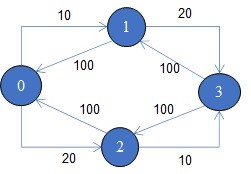

In [ ]:
display(Image('/content/drive/MyDrive/DADOS/S02_Q02.jpg'))

In [ ]:
# Calcular e imprimir a matriz Q
# Valor 0,5

import numpy as np

Q = np.array([
    [-30.0, 10.0, 20.0, 0.0],
    [100.0, -120.0, 0.0, 20.0],
    [100.0, 0.0, -110.0, 10.0],
    [0.0, 100.0, 100.0, -200.0]
], dtype=float)

print("Matriz Q:\n", Q)
print("Somas:", Q.sum(axis=1))



Matriz Q:
 [[ -30.   10.   20.    0.]
 [ 100. -120.    0.   20.]
 [ 100.    0. -110.   10.]
 [   0.  100.  100. -200.]]
Somas: [0. 0. 0. 0.]


In [ ]:
# Calcular e imprimir as probabilidades do regime permanente
# Valor 0,5
pi = cmtcP(Q)
print(f"Probabilidades:{pi}")


Probabilidades:[0.75757576 0.07575758 0.15151515 0.01515152]


In [ ]:
# Calcular e imprimir disponibilidade do cluster
# Valor 0,5

disponibilidade = 1 - pi[3]

print(f"Disponibilidade do cluster: {disponibilidade:.8f}")


Disponibilidade do cluster: 0.98484848


## Disponibilidade

### Questão 3
##### Valor 1,0
Considere um sistema com 6 componentes. O sistema funciona se qualquer uma das duas configurações abaixo estiver operacional:
* Configuração principal: Componentes 1 e 2 em série (ambos devem funcionar).
* Configuração secundária (redundância 2-de-3: pelo menos 2 entre os componentes 3, 4 e 5 devem funcionar (bloco 2-de-3).
* Configuração hot spare: se o componente 6 funciona a configuração funciona.<br>

As disponibilidades dos componentes são:
* A1=0,96
* A2=0,95
* A3=0,90
* A4=0,88
* A5=0,92
* A6= 0,82

Assumindo independência entre os componentes, calcular a disponibilidade de cada configuração e do sistema.

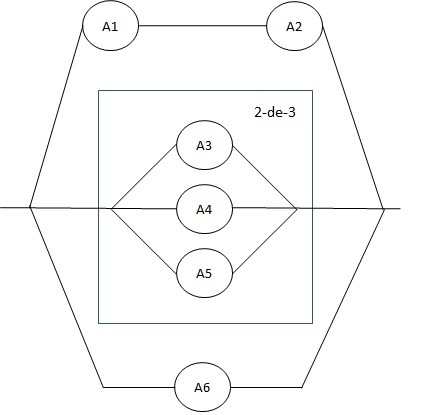

In [ ]:
display(Image('/content/drive/MyDrive/DADOS/S02_Q03.jpg'))

In [ ]:
# Calcular e imprimir a disponibilidade de cada configuração e do sistema
# Formatar impressão para duas casas decimais

A1 = 0.96
A2 = 0.95
A3 = 0.90
A4 = 0.88
A5 = 0.92
A6 = 0.82

U1 = 1 - A1
U2 = 1 - A2
U3 = 1 - A3
U4 = 1 - A4
U5 = 1 - A5
U6 = 1 - A6

D_principal = A1 * A2
print(f"Configuração Principal disponibilidade:{D_principal:.2f}")


# P(A3 e A4 OK, A5 Falha)
D_sec_3_4 = A3 * A4 * U5
# P(A3 e A5 OK, A4 Falha)
D_sec_3_5 = A3 * U4 * A5
# P(A4 e A5 OK, A3 Falha)
D_sec_4_5 = U3 * A4 * A5
# P(A3, A4 e A5 OK)
D_sec_3_4_5 = A3 * A4 * A5

D_secundario = D_sec_3_4 + D_sec_3_5 + D_sec_4_5 + D_sec_3_4_5
print(f"Disponibilidade Configuração Secundária :  {D_secundario:.2f}")

D_hotspare = A6
print(f"Disponibilidade Configuração Hot Spare (Comp. 6): {D_hotspare:.2f}")

D_paralelo_principal = 1 - D_principal
D_paralelo_secundario = 1 - D_secundario
D_paralelo_hotspare = 1 - D_hotspare

D_sistema = D_paralelo_principal * D_paralelo_secundario * D_paralelo_hotspare
D_sistema = 1 - D_sistema
print(f"Disponibilidade do Sistema: {D_sistema:.2f}")


Configuração Principal disponibilidade:0.91
Disponibilidade Configuração Secundária :  0.97
Disponibilidade Configuração Hot Spare (Comp. 6): 0.82
Disponibilidade do Sistema: 1.00


In [ ]:
# Fix dpkg interruption first
!dpkg --configure -a

##################################################################
######    Script para geração de pdf    ##########################
##################################################################

##################################################################
#######    Instalar bibliotecas         ##########################
##################################################################
!apt-get install texlive texlive-xetex texlive-latex-extra pandoc
!pip install pypandoc

##################################################################
#######   Copiar notebook para ambiente collab   #################
##################################################################
nome_notebook = nome +'.ipynb'
path_notebook = '/content/gdrive/MyDrive/Colab Notebooks/' + nome_notebook
!cp "{path_notebook}" ./

##################################################################
#######    Converter para pdf          ###########################
##################################################################
nome_notebook = nome +'.ipynb'
!jupyter nbconvert --to PDF "{nome_notebook}"

##################################################################
#######      Salvar no drive              ########################
##################################################################
nome_pdf = nome +'.pdf'
caminho_local = '/content/'+ nome_pdf
!cp "{caminho_local}" "{caminho_pdf}"

Reading package lists... Done
Building dependency tree... Done
Reading state information... Done
pandoc is already the newest version (2.9.2.1-3ubuntu2).
texlive is already the newest version (2021.20220204-1).
texlive-latex-extra is already the newest version (2021.20220204-1).
texlive-xetex is already the newest version (2021.20220204-1).
0 upgraded, 0 newly installed, 0 to remove and 41 not upgraded.
[NbConvertApp] Converting notebook Somativa02Resposta.ipynb to PDF
[NbConvertApp] Support files will be in Somativa02Resposta_files/
[NbConvertApp] Making directory ./Somativa02Resposta_files
[NbConvertApp] Writing 64077 bytes to notebook.tex
[NbConvertApp] Building PDF
[NbConvertApp] Running xelatex 3 times: ['xelatex', 'notebook.tex', '-quiet']
[NbConvertApp] Running bibtex 1 time: ['bibtex', 'notebook']
[NbConvertApp] WARNING | bibtex had problems, most likely because there were no citations
[NbConvertApp] PDF successfully created
[NbConvertApp] Writing 108008 bytes to Somativa02Resp